# Spectra at random locations, along with initial high-resolution image

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
import sidpy
from scipy.signal import find_peaks
from helper_fns import get_grid_coords, get_subimages, estimate_position_shift

In [2]:
#handy helper function
def det_phase_offset(phase_mat_lin):
    """Input:
        - phase mat: numpy vector of size N, containing the phase values of every point
    Output:
        - phase_offset: float of the phase offset requried to center the phase
        Here centering means that one side will be 0 and the other will be pi,
        so the loop can be projected as A*cos(phi)"""

    #First calculate the histogram of the phase values

    num_bins = 150 #number of bins in histogram
    hist, bin_edges = np.histogram(phase_mat_lin, bins = num_bins)

    #Remove zero values. Sometimes, when phase is undefined the zero bin will have a peak. Remove this,
    #and replace it with the average of the two surrounding bins on either side
    hist[num_bins//2-5:num_bins//2+5] = 0.5*(hist[num_bins//2-5] + hist[num_bins//2+5])

    #Now find the two peaks by finding the two relative maxima

    peak_positions = find_peaks(hist, distance = num_bins//3)

    phase_1 = bin_edges[peak_positions[0][0]]
    phase_2 = bin_edges[peak_positions[0][1]]

    print ('The phase difference is {}'.format(np.round(np.abs(phase_1 - phase_2),3)))
    print ('The phase offset is {}'.format(np.round(phase_1,3)))

    #plt.plot(phase_1, hist[peak_positions[0][0]], 'rx')
    #plt.plot(phase_2, hist[peak_positions[0][1]], 'rx')

    if np.abs(np.abs(phase_1 - phase_2) - np.pi) >0.5:
        print('There was a problem with automatic phase offset determination! Do it manually before proceeding!!')
    phase_offset = phase_1

    return phase_offset

def usid_to_pr(h5_f, sho_fit_group = None):

    """This function takes as an input a h5 path to a USID file for a BEPS measurement,
    and then returns a piezoresponse matrix along with the voltage vector for the first cycle
    Inputs:
    h5_path: string - path to the usid file containing the BEPS measurement

    Output:
    pr_array: numpy ndarray - numpy array containing the piezoresponse matrix in 3D form
    vdc_vec: numpy ndarray - numpy array containing the voltage vector

    """
    #h5_f = h5py.File(h5_path, 'r')
    if sho_fit_group is None:

        sho_mat = h5_f['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Guess']
        spec_val = h5_f['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Spectroscopic_Values']
        pos_inds = h5_f['Measurement_000/Channel_000/Position_Indices']

        #steps_per_cycle = h5_f['Measurement_000'].attrs['VS_steps_per_full_cycle'] * h5_f['Measurement_000'].attrs['VS_number_of_cycles']
    else:
        sho_mat = sho_fit_group['Fit']
        spec_val = sho_fit_group['Spectroscopic_Values']
        pos_inds = sho_fit_group.parent['Position_Indices']

    #steps_per_cycle = h5_f['Measurement_000'].attrs['VS_steps_per_full_cycle'] * h5_f['Measurement_000'].attrs['VS_number_of_cycles']

    pos_dim_sizes = [np.max(pos_inds[:,0])+1, np.max(pos_inds[:,1]+1)]


    #Extract the amplitude and phase from the guess or fit
    sho_mat_ndim = sho_mat[:].reshape(pos_dim_sizes[0], pos_dim_sizes[1], -1)
    amp_mat_ndim = sho_mat_ndim['Amplitude [V]']

    points_measured = sho_mat['Quality Factor'][:,1]!=0
    points_measured = np.where(points_measured==True)[0]

    phase_mat_ndim = sho_mat_ndim['Phase [rad]']
    phase_mat = sho_mat['Phase [rad]']

    #First calculate phase offset

    #Be careful for this: we need to exclude points that have not been measured!
    phase_mat_ndim_measured = phase_mat.copy()[points_measured,:]
    phase_offset = 0#1.75#det_phase_offset(phase_mat_ndim_measured.ravel())

#     pr_mat_ndim_real = (amp_mat_ndim*np.cos(phase_mat_ndim-phase_offset))[:,:,steps_per_cycle:]
#     pr_mat_ndim_imag = (amp_mat_ndim*np.sin(phase_mat_ndim-phase_offset))[:,:,steps_per_cycle:]
    pr_mat_ndim_real_all = (amp_mat_ndim*np.cos(phase_mat_ndim-phase_offset))
    pr_mat_ndim_imag_all = (amp_mat_ndim*np.sin(phase_mat_ndim-phase_offset))

    pr_mat_ndim_real = np.zeros((128,128,256))
    pr_mat_ndim_imag = np.zeros((128,128,256))
    # for k in range (64*3):
    #     pr_mat_ndim_real[:,:,k] = pr_mat_ndim_real_all[:,:,k*2+1]
    #     pr_mat_ndim_imag[:,:,k] = pr_mat_ndim_imag_all[:,:,k*2+1]

    vdc = spec_val[0,:]
    # vdc_vec = np.zeros(int(len(vdc)/2))
    # for i in range (int(len(vdc)/2)):
    #     vdc_vec [i] = vdc[i*2]

    h5_f.close()

    # return [pr_mat_ndim_real, pr_mat_ndim_imag], vdc_vec, points_measured
    return [pr_mat_ndim_real, pr_mat_ndim_imag], vdc, points_measured

# cAFM IV at Random Locations

Load image data

In [3]:
cAFMmap = h5py.File('content/V3_IV_map_1d2um_0002.h5', 'r')
sidpy.hdf_utils.print_tree(cAFMmap)

/
├ Measurement_000
  ---------------
  ├ Channel_000
    -----------
    ├ Bin_FFT
    ├ Bin_Frequencies
    ├ Bin_Indices
    ├ Bin_Step
    ├ Bin_Wfm_Type
    ├ Excitation_Waveform
    ├ Noise_Floor
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Raw_Data-SHO_Fit_000
      --------------------
      ├ Guess
      ├ Spectroscopic_Indices
      ├ Spectroscopic_Values
    ├ Spatially_Averaged_Plot_Group_000
      ---------------------------------
      ├ Bin_Frequencies
      ├ Mean_Spectrogram
      ├ Spectroscopic_Parameter
      ├ Step_Averaged_Response
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
    ├ UDVS
    ├ UDVS_Indices
  ├ Channel_001
    -----------
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
  ├ Channel_002
    -----------
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
  ├ Channel_003
    -----------
    ├ Po

In [4]:
rz = 128  #set the size of dataset

topo = cAFMmap['Measurement_000/Channel_001/Raw_Data']['r'].reshape(rz,rz)
cmap = cAFMmap['Measurement_000/Channel_002/Raw_Data']['r'].reshape(rz,rz)
defl = cAFMmap['Measurement_000/Channel_003/Raw_Data']['r'].reshape(rz,rz)

(np.float64(-0.5), np.float64(127.5), np.float64(-0.5), np.float64(127.5))

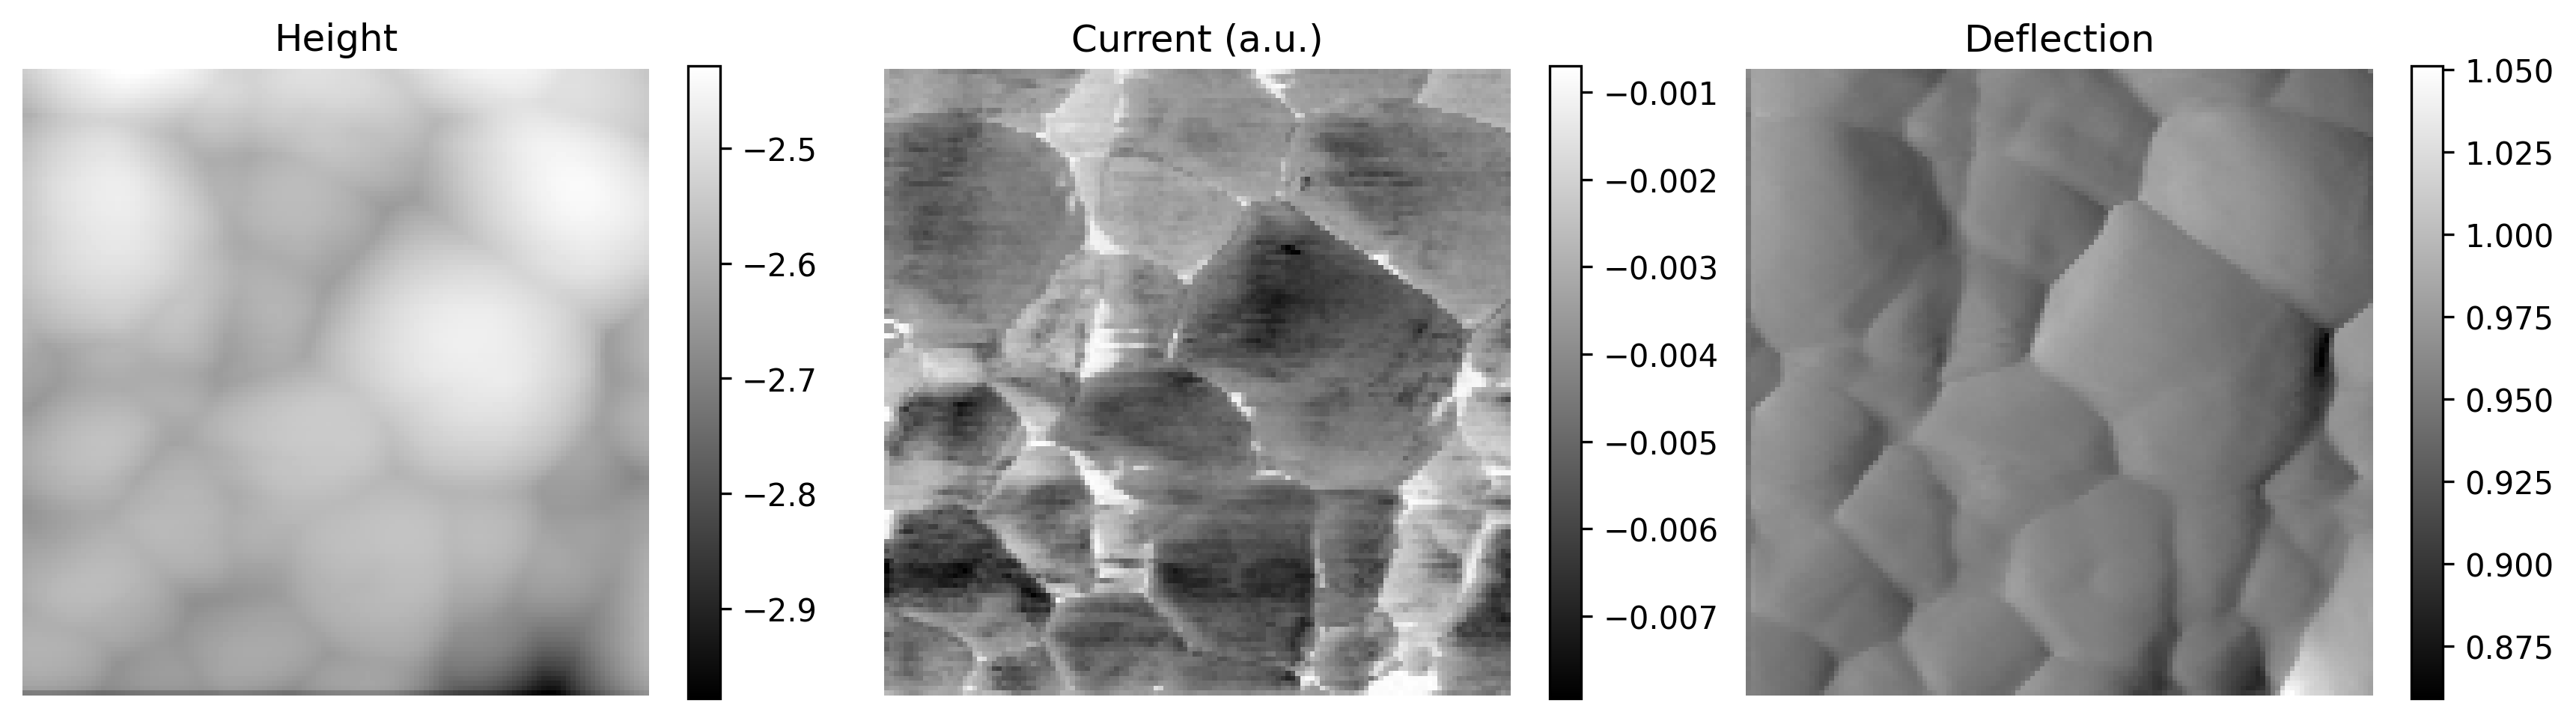

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4), dpi = 300)
fig.subplots_adjust(left=0.02, bottom=0.06, right=0.95, top=0.94, wspace=0.1)
# Make 4 subplots:
cm = 'gray'
shrink = 0.8

im1 = axs[0].imshow(topo, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im1, ax=axs[0], shrink = shrink)
#axs[0, 0].set_title("Amplitude (µV)")
axs[0].set_title("Height")
axs[0].axis('off')

im2 = axs[1].imshow(cmap, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im2, ax=axs[1], shrink = shrink)
axs[1].set_title("Current (a.u.)")
axs[1].axis('off')

im3 = axs[2].imshow(defl, interpolation='nearest', origin = "lower", cmap=cm)
fig.colorbar(im3, ax=axs[2], shrink = shrink)
axs[2].set_title("Deflection")
axs[2].axis('off')

Load spectra data

In [6]:
IVspec = h5py.File('content/V3_IV_spec_1d2um_0003.h5', 'r')
sidpy.hdf_utils.print_tree(IVspec)

/
├ Measurement_000
  ---------------
  ├ Channel_000
    -----------
    ├ Bin_FFT
    ├ Bin_Frequencies
    ├ Bin_Indices
    ├ Bin_Step
    ├ Excitation_Waveform
    ├ Noise_Floor
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Raw_Data-SHO_Fit_000
      --------------------
      ├ Guess
      ├ Spectroscopic_Indices
      ├ Spectroscopic_Values
    ├ Spatially_Averaged_Plot_Group_000
      ---------------------------------
      ├ Bin_Frequencies
      ├ Mean_Spectrogram
      ├ Spectroscopic_Parameter
      ├ Step_Averaged_Response
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
    ├ UDVS
    ├ UDVS_Indices
  ├ Channel_001
    -----------
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
  ├ Channel_002
    -----------
    ├ Position_Indices
    ├ Position_Values
    ├ Raw_Data
    ├ Spectroscopic_Indices
    ├ Spectroscopic_Values
  ├ Channel_003
    -----------
    ├ Position_Indices
    

extract spectra from measured points

In [7]:
IV = IVspec['Measurement_000/Channel_002/Raw_Data']['r']
IVmap = IV.reshape((128, 128, -1))

IV_height = IVspec['Measurement_000/Channel_001/Raw_Data']['r']  # height recorded during each IV (used in the checks below)

spec_val = IVspec['Measurement_000/Channel_000/Raw_Data-SHO_Fit_000/Spectroscopic_Values']

#extract spectra from measured points
_, v_step, points_measured = usid_to_pr(IVspec)
measured_IV = IV[points_measured,]

Text(0, 0.5, 'Current (nA)')

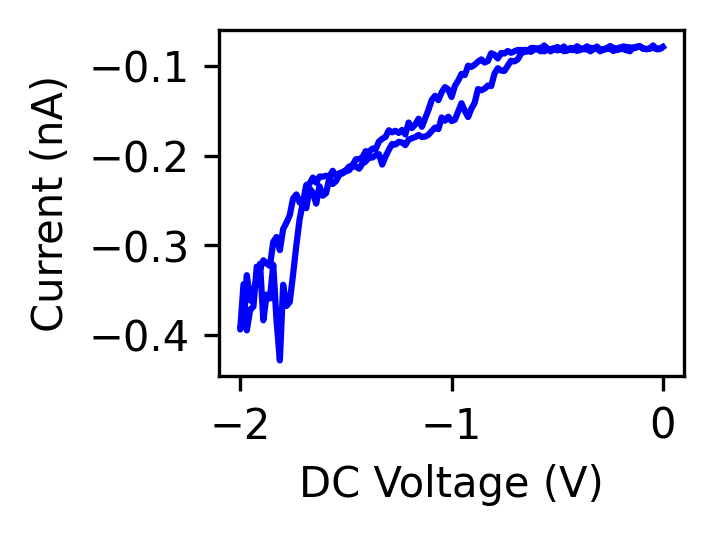

In [8]:
plt.figure(figsize = (2, 1.5), dpi = 300)
plt.plot(v_step, measured_IV[300, ]*100, c = 'b')
plt.xlabel("DC Voltage (V)")
plt.ylabel("Current (nA)")

In [22]:
from scipy.signal import savgol_filter
k = 100
for i in range (20):
  y = measured_IV[i*k, ]
  step = v_step
  yhat = savgol_filter(y, 55, 5)
  der = np.gradient(yhat, step)

  # plt.plot(step, y, c = 'b')
  # plt.plot(step, yhat, c = 'green')
  # #plt.plot(step, der, c = 'r')
  # plt.xlabel("voltage (V)")
  # plt.ylabel("Current (a.u.)")
  # plt.show()
  
  
  loc = np.where(der>0.002)
  if len(loc[0])==0:
    print('turn on voltage is 2.5V')
  else:
    print(step[loc[0][0]])

-1.640625
-1.015625
-1.796875
-0.75
turn on voltage is 2.5V
-0.859375
-0.671875
-0.546875
-1.34375
-1.734375
-1.375
-0.53125
-0.859375
-0.71875
-0.75
-0.703125
-0.78125
-0.59375
-1.015625
-0.4375


Turn on voltage

In [10]:
V_turn_on = []
for i in range (len(measured_IV)):
  y = measured_IV[i, :128]
  step = v_step[:128]
  yhat = savgol_filter(y, 55, 5)
  der = np.gradient(yhat, step)

  loc = np.where(der>0.002)
  if len(loc[0])==0:
    V_turn_on.append(-2.1)
  else:
    V_turn_on.append(step[loc[0][0]])

smoothed IV

In [11]:
smoothed_IV = np.zeros(measured_IV.shape)
for i in range (len(measured_IV)):
  y = measured_IV[i,]
  step = v_step
  yhat = savgol_filter(y, 55, 5)
  smoothed_IV[i, ] = yhat
smoothed_IV.shape

(2001, 256)

Show measured points

Prepare image and spectra data for train---need to link corresponding image patches and spectra

(2001, 2)
(2001, 30, 30)


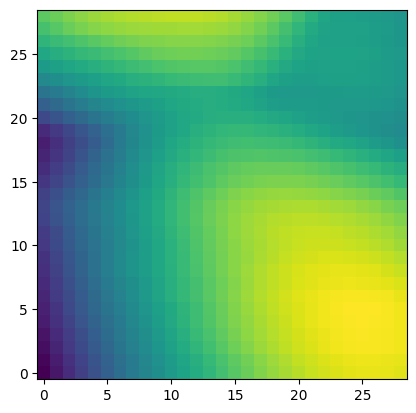

In [12]:
image = topo
coor = get_grid_coords(image, 1)
coor = coor[points_measured]

windowsize = 30
img, com, valid_idx = get_subimages(image, coor, windowsize)
assert len(valid_idx) == len(coor), "some patches were skipped: select the spectra with valid_idx"

indices = np.asarray(com, dtype= int)
print(indices.shape)
img = img[:,:,:,0]
plt.imshow(img[2000,1:,1:], origin = 'lower')
print(img.shape)

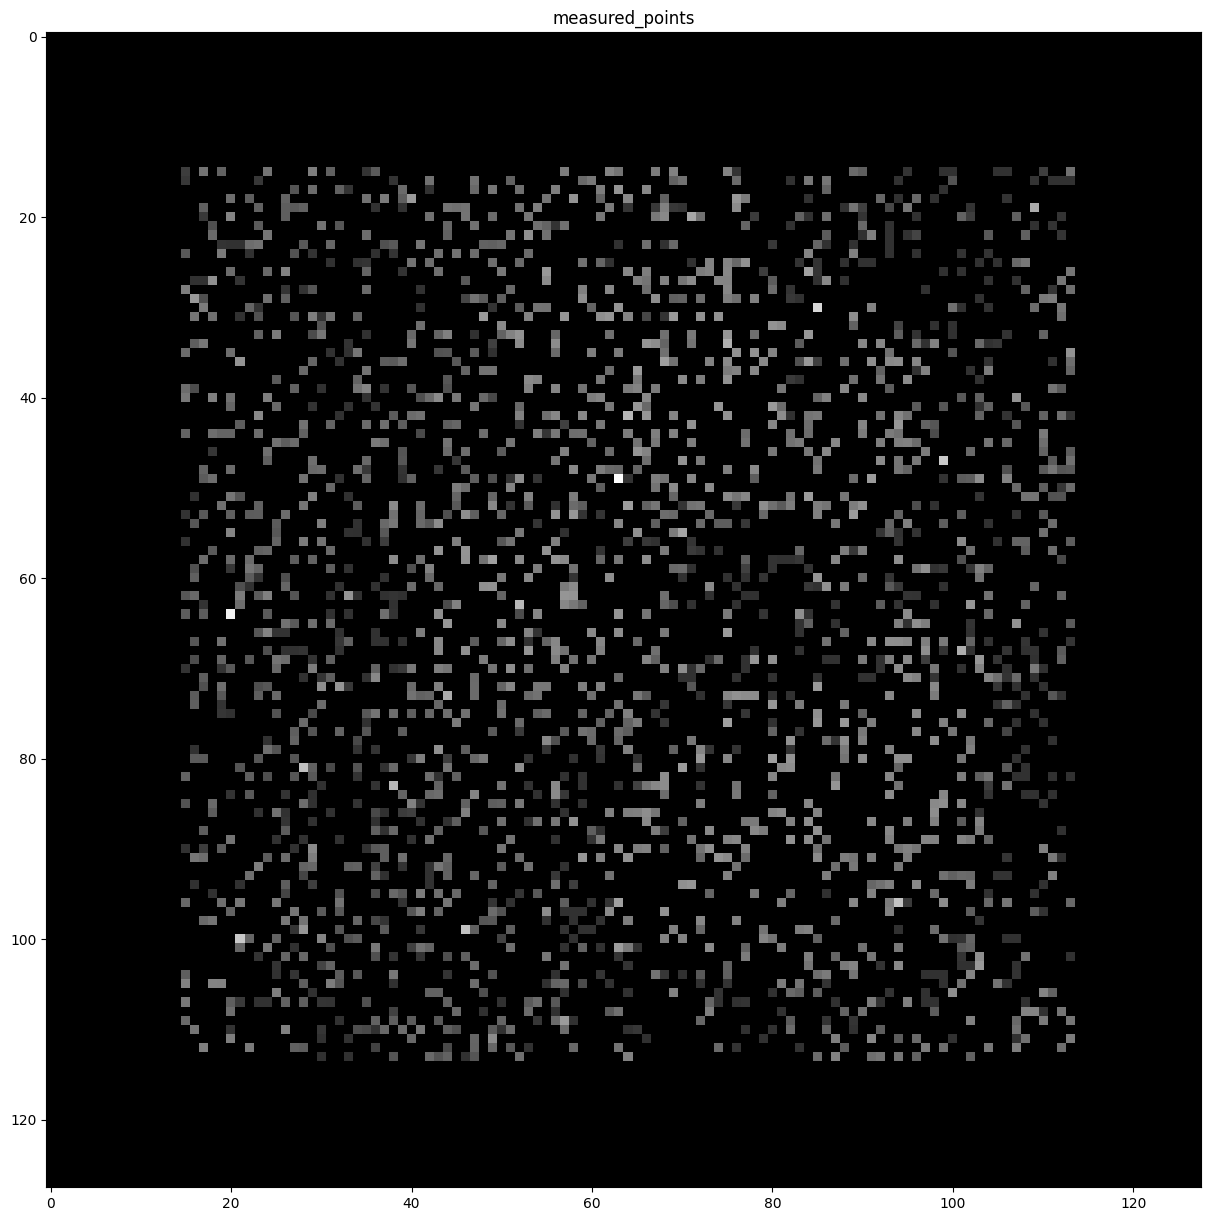

In [13]:
plt.figure(figsize = (15, 15))
plt.title("measured_points")
plt.imshow(IVmap.mean(2), cmap = 'Greys')

Show corresponding image patches and spectra

In [25]:
k = 1000
for k in range (10):
  #_, (ax1, ax2) = plt.subplots(1,2, figsize = (15, 5))
  
  # ax1.imshow(img[k*100,])
  # ax1.axis('off')
  # ax2.plot(v_step, smoothed_IV[k*100,])
  plt.show()

# Data integrity checks

In [15]:
# Data integrity checks
n_pix = IV.shape[0]
measured_mask = np.zeros(n_pix, bool); measured_mask[points_measured] = True
print(f"grid {topo.shape}, spectra per pixel {IV.shape[1]}, measured points {len(points_measured)} (unique {len(np.unique(points_measured))})")
print("NaNs: image", np.isnan(topo).sum(), "| IV", np.isnan(IV).sum())
print("unmeasured pixels with nonzero IV:", int((np.abs(IV[~measured_mask]).sum(1) > 0).sum()))
print("measured pixels with all-zero IV: ", int((np.abs(measured_IV).sum(1) == 0).sum()))
print(f"v_step: {len(v_step)} points, {v_step[0]:.3f} -> {v_step.min():.3f} V (index {v_step.argmin()}) -> {v_step[-1]:.3f} V")
rows, cols = coor.T
print(f"point rows {rows.min()}-{rows.max()}, cols {cols.min()}-{cols.max()}; "
      f"largest window with no skipped points: {2 * min(rows.min(), cols.min(), topo.shape[0] - rows.max(), topo.shape[1] - cols.max())}")
assert np.array_equal(coor[:, 0] * topo.shape[1] + coor[:, 1], points_measured), "coordinate / spectrum order mismatch"
print("coordinates match the spectrum order: OK")


grid (128, 128), spectra per pixel 256, measured points 2001 (unique 2001)
NaNs: image 0 | IV 0
unmeasured pixels with nonzero IV: 0
measured pixels with all-zero IV:  0
v_step: 256 points, 0.000 -> -2.000 V (index 128) -> -0.016 V
point rows 15-113, cols 15-113; largest window with no skipped points: 30
coordinates match the spectrum order: OK


Position check: compare the map topography at each IV point with the height recorded during that IV (both with a plane removed).
A best shift far from (0, 0) means the tip/sample drifted between the image and the IV grid.

corr at recorded positions 0.39; best shift (drow, dcol) = (-12, 7), corr 0.82


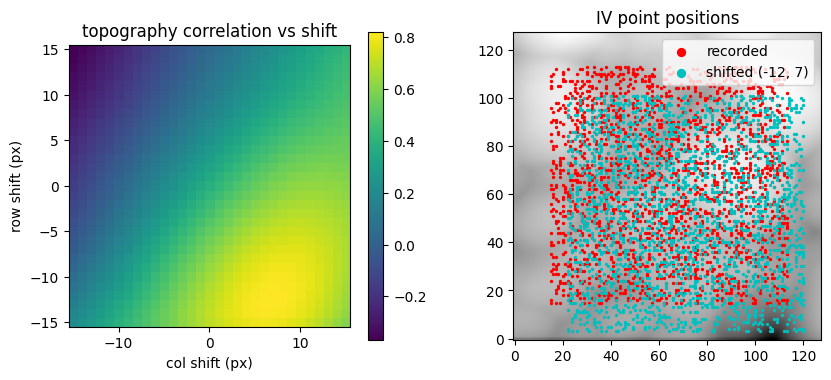

In [16]:
point_heights = IV_height[points_measured].mean(1)
shift = estimate_position_shift(topo, coor, point_heights, max_shift=15)
print(f"corr at recorded positions {shift['corr_at_zero']:.2f}; best shift (drow, dcol) = {shift['best_shift']}, corr {shift['best_corr']:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(shift["corr_map"], origin="lower", extent=[-15.5, 15.5, -15.5, 15.5], cmap="viridis")
ax[0].set_xlabel("col shift (px)"); ax[0].set_ylabel("row shift (px)"); ax[0].set_title("topography correlation vs shift")
fig.colorbar(im, ax=ax[0])
dy, dx = shift["best_shift"]
ax[1].imshow(topo, origin="lower", cmap="gray")
ax[1].scatter(coor[:, 1], coor[:, 0], s=2, c="r", label="recorded")
ax[1].scatter(coor[:, 1] + dx, coor[:, 0] + dy, s=2, c="c", label=f"shifted ({dy}, {dx})")
ax[1].legend(loc="upper right", markerscale=4); ax[1].set_title("IV point positions")
plt.show()


# Save Random IV as npz

In [17]:
# np.savez('random_IV_MHP.npz', fullimg = image, imgpatches = img[:,1:-1,1:-1], spectra = smoothed_IV,
#          v_step = v_step, coordinates = coor)

# Position offset between the image and the IV points

During each IV curve the tip height was also recorded (`Channel_001` of the spectra file). If the IV points sit where the
coordinates say, these heights should follow the map topography at the same pixels. Below, both are shown with a fitted plane
removed (the sample tilt), first at the recorded positions and then shifted by the best offset found in the position check above.

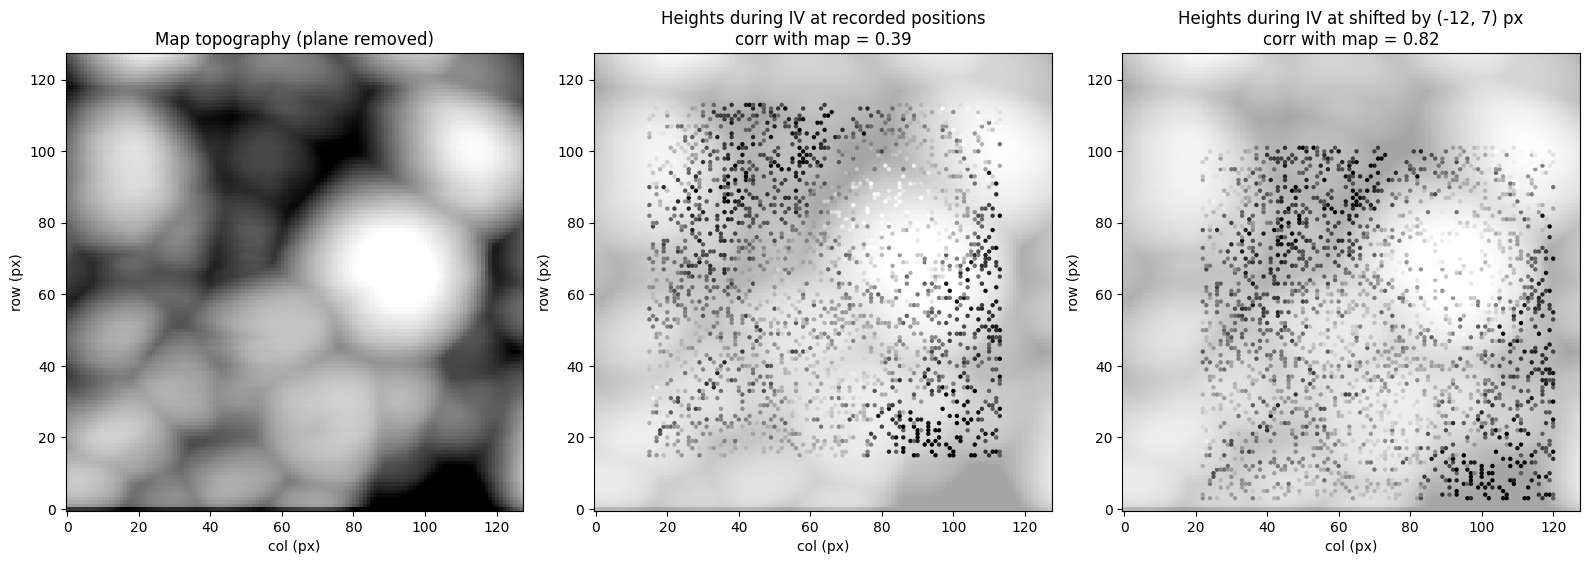

best shift: -12 rows, 7 cols  (about -112 nm, 66 nm)


In [18]:
from helper_fns import remove_plane

dy, dx = shift["best_shift"]
H, W = topo.shape
rr, cc = np.mgrid[:H, :W]
topo_flat = remove_plane(topo.ravel(), rr.ravel(), cc.ravel()).reshape(H, W)
heights_flat = remove_plane(point_heights, coor[:, 0], coor[:, 1])
vmin, vmax = np.percentile(topo_flat, [2, 98])
nm_per_px = 1.2e3 / H   # 1.2 um scan, 128 px

fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
axs[0].imshow(topo_flat, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
axs[0].set_title("Map topography (plane removed)")
for ax, (sy, sx), name in ((axs[1], (0, 0), "recorded positions"), (axs[2], (dy, dx), f"shifted by ({dy}, {dx}) px")):
    r, c = coor[:, 0] + sy, coor[:, 1] + sx
    ok = (r >= 0) & (r < H) & (c >= 0) & (c < W)
    corr = np.corrcoef(topo_flat[r[ok], c[ok]], heights_flat[ok])[0, 1]
    ax.imshow(topo_flat, origin="lower", cmap="gray", vmin=vmin, vmax=vmax, alpha=0.35)
    ax.scatter(c, r, c=heights_flat, s=10, cmap="gray", vmin=vmin, vmax=vmax, edgecolors="none")
    ax.set_xlim(-0.5, W - 0.5); ax.set_ylim(-0.5, H - 0.5)
    ax.set_title(f"Heights during IV at {name}\ncorr with map = {corr:.2f}")
for ax in axs:
    ax.set_xlabel("col (px)"); ax.set_ylabel("row (px)")
plt.tight_layout(); plt.show()
print(f"best shift: {dy} rows, {dx} cols  (about {dy * nm_per_px:.0f} nm, {dx * nm_per_px:.0f} nm)")


Height recorded during each IV against the map height at the same pixel, before and after the shift. A good alignment gives points along the diagonal.

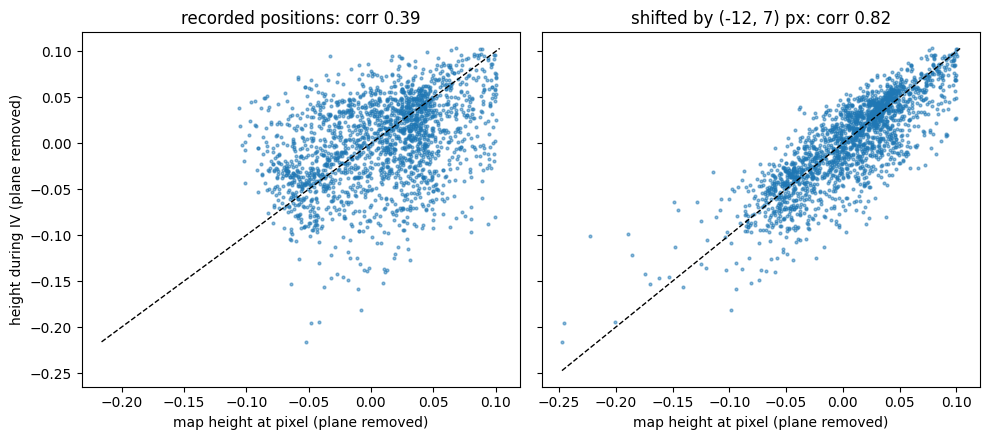

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (sy, sx), name in ((axs[0], (0, 0), "recorded positions"), (axs[1], (dy, dx), f"shifted by ({dy}, {dx}) px")):
    r, c = coor[:, 0] + sy, coor[:, 1] + sx
    ok = (r >= 0) & (r < H) & (c >= 0) & (c < W)
    x, y = topo_flat[r[ok], c[ok]], heights_flat[ok]
    ax.scatter(x, y, s=4, alpha=0.5)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(f"{name}: corr {np.corrcoef(x, y)[0, 1]:.2f}")
    ax.set_xlabel("map height at pixel (plane removed)")
axs[0].set_ylabel("height during IV (plane removed)")
plt.tight_layout(); plt.show()


Correlation along each shift direction through the best shift (cuts through the correlation map above).

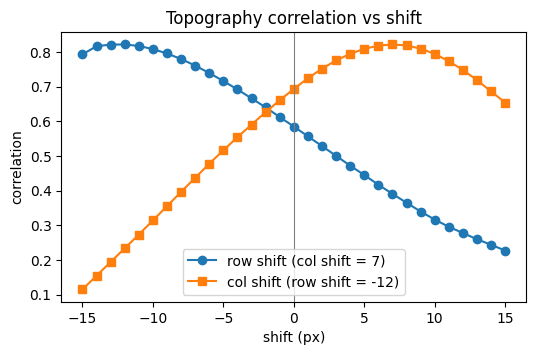

In [20]:
ms = (shift["corr_map"].shape[0] - 1) // 2
s = np.arange(-ms, ms + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(s, shift["corr_map"][:, dx + ms], "o-", label=f"row shift (col shift = {dx})")
plt.plot(s, shift["corr_map"][dy + ms, :], "s-", label=f"col shift (row shift = {dy})")
plt.axvline(0, c="gray", lw=0.8)
plt.xlabel("shift (px)"); plt.ylabel("correlation"); plt.legend(); plt.title("Topography correlation vs shift")
plt.show()


Example patches: the patch the notebook currently pairs with each spectrum (recorded position) and the patch at the shifted position. Red cross = patch centre (spectrum location).

1640 of 2001 shifted points fit a 30x30 patch without padding


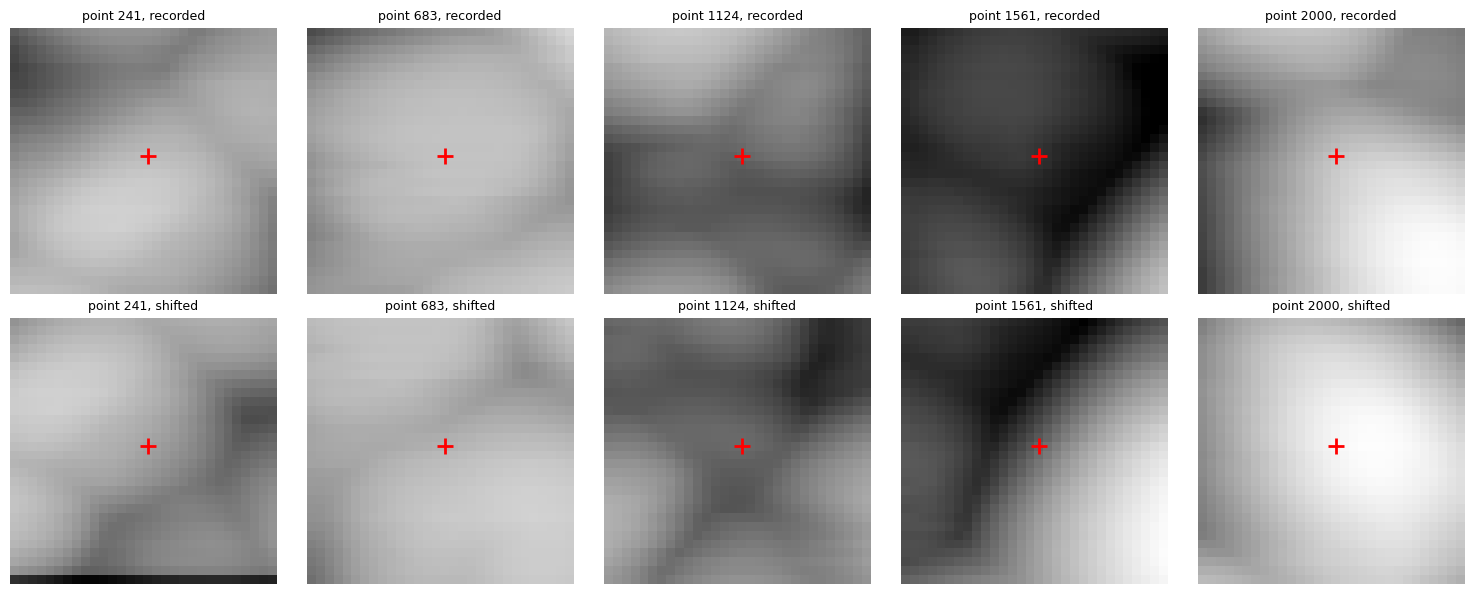

In [21]:
half = windowsize // 2
r_s, c_s = coor[:, 0] + dy, coor[:, 1] + dx
fits = np.where((r_s - half >= 0) & (r_s + half <= H) & (c_s - half >= 0) & (c_s + half <= W))[0]
print(f"{len(fits)} of {len(coor)} shifted points fit a {windowsize}x{windowsize} patch without padding")
examples = fits[np.linspace(0, len(fits) - 1, 5).astype(int)]

fig, axs = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6))
for j, k in enumerate(examples):
    for i, (r0, c0, name) in enumerate(((coor[k, 0], coor[k, 1], "recorded"), (r_s[k], c_s[k], "shifted"))):
        patch = topo_flat[r0 - half:r0 + half, c0 - half:c0 + half]
        axs[i, j].imshow(patch, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
        axs[i, j].plot(half, half, "r+", ms=12, mew=2)
        axs[i, j].set_title(f"point {k}, {name}", fontsize=9); axs[i, j].axis("off")
plt.tight_layout(); plt.show()
